# Philadelphia Restaurant Recommender: Data and Retrieval Decisions

This is a record of the analysis supporting the finalized data and index setup.

1. Validate and scope the immutable data
2. Normalize useful attributes and inspect coverage
3. Preserve review evidence and define temporal evaluation
4. Prepare training only personalization inputs
5. Summarize the chosen BM25 + Gemma retrieval setup
6. Export finalized inputs and check index readiness

**Decisions:** Philadelphia, PA; Restaurants tagged businesses; all eligible reviews; BM25 + EmbeddingGemma with reciprocal rank fusion; separate evaluation and historical serving indexes. No reranker.

Run top to bottom after analytical preparation. Data checks and normalization are recomputed; completed retrieval judgments/rankings are read from saved artifacts. No models download, API calls, reserved-query scoring, or index building occurs here.

In [ ]:
import ast
import json
import runpy
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config_project.yaml').exists())
sys.path.insert(0, str(ROOT / 'src'))
from recommender.prep_baseline import sql_string

CFG = yaml.safe_load((ROOT / 'config_project.yaml').read_text())
MANIFEST = json.loads((ROOT / 'data/processed/analytical/active.json').read_text())
CORE = ROOT / 'data/processed/analytical' / MANIFEST['run']
EDA = ROOT / 'data/processed/eda' / MANIFEST['run']
OUT = EDA / 'final_decisions'
OUT.mkdir(parents=True, exist_ok=True)
TRAIN_END = CFG['evaluation']['train_end']
VALID_END = CFG['evaluation']['validation_end']
SEED = CFG['retrieval']['seed']

con = duckdb.connect()
con.execute("SET memory_limit='4GB'")
con.execute("SET threads=2")
con.execute("SET temp_directory=" + sql_string(OUT / 'duckdb_tmp'))
con.read_parquet(str(CORE / 'restaurants.parquet')).create_view('businesses')
con.read_parquet(str(CORE / 'reviews.parquet')).create_view('core_reviews')


def q(sql):
    return con.execute(sql).df()


def figure(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=140, bbox_inches='tight')
    plt.show()


plt.rcParams.update(
    {'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False}
)
pd.set_option('display.max_colwidth', 85)
print("Analytical version:", MANIFEST['run'])

Analytical version: 8edf7f143f8740358708c0ed78dfb83a


## 1. Philadelphia scope and data integrity

Normalize city case, Unicode and whitespace before selecting Philadelphia + PA. Suburbs and separately named Southwest Philadelphia are excluded. Preserve the full immutable core; apply project scope only to derived inputs.

In [ ]:
business = q("SELECT * EXCLUDE(attributes,hours) FROM businesses")
normalized = business.copy()
normalized['city_normalized'] = normalized.city.str.normalize('NFKC').str.strip().str.casefold()
normalized['state_normalized'] = normalized.state.str.strip().str.upper()
normalized['price_known'] = normalized.price.notna()
normalized['coordinates_valid'] = normalized.latitude.between(
    -90, 90
) & normalized.longitude.between(-180, 180)

in_scope = normalized.city_normalized.eq(
    CFG['scope']['city_normalized']
) & normalized.state_normalized.eq(CFG['scope']['state_normalized'])
city = normalized.loc[in_scope].copy()
con.register('philadelphia_ids', city[['business_id']])
con.execute(
    "CREATE VIEW reviews AS SELECT * FROM core_reviews SEMI JOIN philadelphia_ids USING(business_id)"
)

summary = q("""SELECT count(*) reviews,count(DISTINCT user_id) users,
    count(DISTINCT business_id) reviewed_restaurants,min(date) first_review,max(date) last_review
    FROM reviews""")
summary.insert(0, 'restaurants', len(city))
display(summary)
display(city.groupby(['city', 'state']).size().rename('restaurants').to_frame())

,restaurants,reviews,users,reviewed_restaurants,first_review,last_review
0,5855,687553,209578,5855,2005-02-16 04:06:26,2022-01-19 19:46:34


,,restaurants
city,state,
Philadelphia,PA,5852
Philadelphia,PA,1
philadelphia,PA,2


In [ ]:
checks = q("""SELECT count(*)-count(DISTINCT review_id) duplicate_review_ids,
    count(*) FILTER(WHERE review_id IS NULL OR user_id IS NULL OR trim(user_id)='') missing_ids,
    count(*) FILTER(WHERE date IS NULL) missing_dates,
    count(*) FILTER(WHERE stars IS NULL OR stars NOT BETWEEN 1 AND 5) invalid_ratings,
    count(*) FILTER(WHERE text IS NULL OR trim(text)='') blank_text,
    (SELECT count(*) FROM reviews ANTI JOIN businesses USING(business_id)) orphan_reviews
    FROM reviews""")
assert normalized.business_id.notna().all() and normalized.business_id.is_unique
assert checks.drop(columns='blank_text').iloc[0].eq(0).all()
display(checks)

pairs = q("""SELECT count(*) repeated_pairs,coalesce(sum(n-1),0) additional_reviews
    FROM (SELECT user_id,business_id,count(*) n FROM reviews GROUP BY ALL HAVING n>1)""")
display(pairs)
print("Repeated visits remain source interactions; they are not duplicate review IDs.")

,duplicate_review_ids,missing_ids,missing_dates,invalid_ratings,blank_text,orphan_reviews
0,0,0,0,0,0,0


,repeated_pairs,additional_reviews
0,19322,21536.0


Repeated visits remain source interactions; they are not duplicate review IDs.


### Geographic consistency

Coordinate range checks alone miss mislabeled locations. Retain the audited empirical metro anchor check: flag a business when its labeled state anchor is over 150 km away but another anchor is within 75 km. Flags require review.

In [4]:
anchors = q("""SELECT state,median(latitude) lat,median(longitude) lon,count(*) n
 FROM businesses GROUP BY state HAVING count(*)>=100 ORDER BY state""")


def distance_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = [np.radians(v) for v in (lat1, lon1, lat2, lon2)]
    a = (
        np.sin((lat2 - lat1) / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    )
    return 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

,restaurants
needs_review,
False,5855


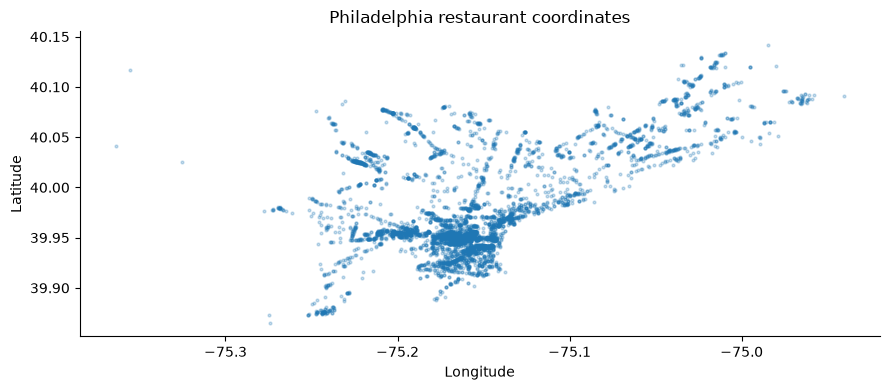

In [ ]:
geo_audit = normalized[
    ['business_id', 'name', 'city', 'state', 'latitude', 'longitude', 'coordinates_valid']
].copy()
distances = distance_km(
    geo_audit.latitude.to_numpy()[:, None],
    geo_audit.longitude.to_numpy()[:, None],
    anchors.lat.to_numpy(),
    anchors.lon.to_numpy(),
)
nearest = distances.argmin(axis=1)
geo_audit['nearest_anchor_state'] = anchors.state.to_numpy()[nearest]
geo_audit['nearest_anchor_km'] = distances[np.arange(len(geo_audit)), nearest]
anchor_lookup = anchors.set_index('state')
geo_audit['labeled_anchor_km'] = distance_km(
    geo_audit.latitude,
    geo_audit.longitude,
    geo_audit.state.map(anchor_lookup.lat),
    geo_audit.state.map(anchor_lookup.lon),
)
geo_audit['geo_review_needed'] = (
    ~geo_audit.coordinates_valid
    | geo_audit.labeled_anchor_km.isna()
    | ((geo_audit.labeled_anchor_km > 150) & (geo_audit.nearest_anchor_km < 75))
)

city_geo = geo_audit.loc[geo_audit.business_id.isin(city.business_id)]
display(
    city_geo.geo_review_needed.value_counts().rename_axis('needs_review').to_frame('restaurants')
)
plt.scatter(city.longitude, city.latitude, s=4, alpha=0.25)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Philadelphia restaurant coordinates")
figure('philadelphia_geography')

## 2. Attribute normalization and usable coverage

Use price, delivery, takeout and outdoor seating as structured filters. Parse literal booleans safely and preserve unknowns. Keep original attributes/hours for traceability; low coverage does not justify deleting source fields. Do not infer dietary safety from a cuisine tag or claim live opening hours.

In [6]:
attrs = q("""SELECT business_id,attributes.RestaurantsDelivery delivery_raw,
    attributes.RestaurantsTakeOut takeout_raw,attributes.OutdoorSeating outdoor_raw
    FROM businesses""")


def parse_attribute(value):
    if value is None or (isinstance(value, float) and pd.isna(value)):
        return None
    try:
        return ast.literal_eval(value) if isinstance(value, str) else value
    except (ValueError, SyntaxError):
        return None


parse_rows = []
for source, destination in [
    ('delivery_raw', 'delivery'),
    ('takeout_raw', 'takeout'),
    ('outdoor_raw', 'outdoor_seating'),
]:
    parsed = attrs[source].map(parse_attribute)
    attrs[destination] = pd.array(
        [v if isinstance(v, bool) else None for v in parsed], dtype='boolean'
    )
    scoped_raw = attrs.loc[attrs.business_id.isin(city.business_id), source]
    scoped_parsed = scoped_raw.map(parse_attribute)
    parse_rows.append(
        {
            'attribute': destination,
            'raw_missing': scoped_raw.isna().sum(),
            'usable_boolean': scoped_parsed.map(lambda v: isinstance(v, bool)).sum(),
            'other_or_literal_none': (
                scoped_raw.notna() & ~scoped_parsed.map(lambda v: isinstance(v, bool))
            ).sum(),
        }
    )

normalized = normalized.merge(
    attrs[['business_id', 'delivery', 'takeout', 'outdoor_seating']],
    on='business_id',
    validate='one_to_one',
)
city = normalized.loc[normalized.business_id.isin(city.business_id)].copy()
display(pd.DataFrame(parse_rows).set_index('attribute'))

,raw_missing,usable_boolean,other_or_literal_none
attribute,,,
delivery,461,5083,311
takeout,360,5341,154
outdoor_seating,983,4707,165


,known_fraction
price,84.4%
delivery,86.8%
takeout,91.2%
outdoor_seating,80.4%


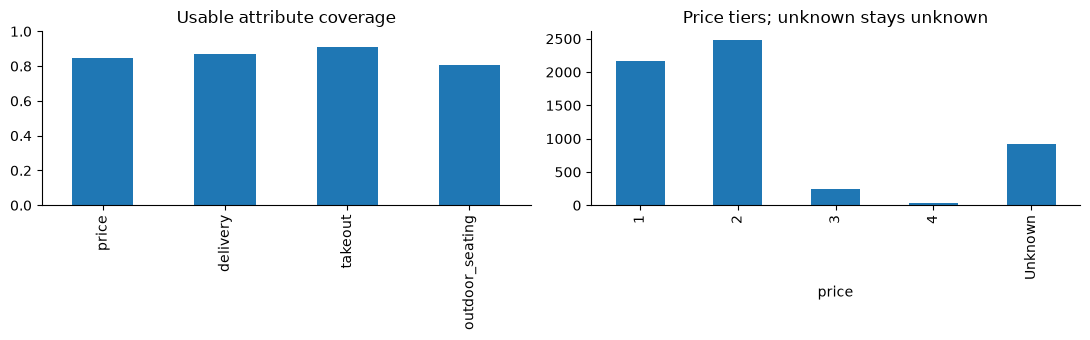

,restaurants
category,
nightlife,1037
bars,981
sandwiches,929
pizza,800
american (new),751
breakfast & brunch,687
american (traditional),663
coffee & tea,575
italian,505


In [ ]:
coverage = (
    city[['price', 'delivery', 'takeout', 'outdoor_seating']]
    .notna()
    .mean()
    .rename('known_fraction')
)
display(coverage.to_frame().style.format('{:.1%}'))
assert city.price.dropna().isin([1, 2, 3, 4]).all()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
coverage.plot.bar(ax=axes[0], ylim=(0, 1), title="Usable attribute coverage")
city.price.astype('Int64').astype('string').fillna('Unknown').value_counts().sort_index().plot.bar(
    ax=axes[1], title="Price tiers; unknown stays unknown"
)
figure('attribute_coverage')

category = (
    normalized[['business_id', 'categories']]
    .assign(category=normalized.categories.str.split(','))
    .explode('category')
)
category['category'] = category.category.str.strip().str.casefold()
category = category[['business_id', 'category']].drop_duplicates()
city_categories = category.loc[category.business_id.isin(city.business_id)]
assert set(city.business_id) <= set(
    city_categories.loc[city_categories.category.eq('restaurants'), 'business_id']
)
display(
    city_categories.loc[~city_categories.category.isin(['restaurants', 'food']), 'category']
    .value_counts()
    .head(12)
    .to_frame('restaurants')
)

**Decision:** explicit positive metadata is required for a strict filter; missing does not mean false or affordable. Categories remain nonexclusive labels, not a finalized cuisine ontology. Retain Restaurants-tag scope; cafes/bars without that tag are outside this project's catalog.

## 3. Preserve evidence and separate time periods

Keep all eligible reviews, including negative and conflicting accounts, without a recent review cap. The previous evidence checks showed that a few recent reviews can omit rarer aspects. Chunking preserves source text, IDs, dates and offsets; it does not rewrite or summarize reviews.

Train before 2020; validate during 2020; hold out 2021 onward. Review dates are publication dates. Pandemic shift and snapshot business metadata limit historical interpretation; do not filter historical evaluation using snapshot open status.

,split,reviews,users,restaurants,first_review,last_review
0,train,613966,185997,5519,2005-02-16 04:06:26,2019-12-31 23:49:03
1,validation,34936,18877,3238,2020-01-01 00:10:10,2020-12-31 23:58:43
2,test,38651,20399,3079,2021-01-01 00:00:31,2022-01-19 19:46:34


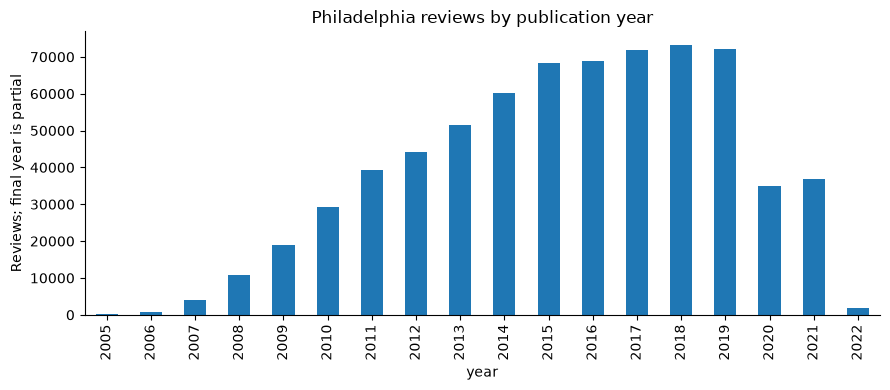

In [ ]:
for name, condition in [
    ('train', f"date < TIMESTAMP '{TRAIN_END}'"),
    ('validation', f"date >= TIMESTAMP '{TRAIN_END}' AND date < TIMESTAMP '{VALID_END}'"),
    ('test', f"date >= TIMESTAMP '{VALID_END}'"),
]:
    con.execute(f"CREATE VIEW {name} AS SELECT * FROM reviews WHERE {condition}")

splits = pd.concat(
    [
        q(f"""SELECT '{name}' split,count(*) reviews,count(DISTINCT user_id) users,
    count(DISTINCT business_id) restaurants,min(date) first_review,max(date) last_review FROM {name}""")
        for name in ['train', 'validation', 'test']
    ],
    ignore_index=True,
)
assert splits.reviews.sum() == summary.reviews.iloc[0]
display(splits)

annual = q("SELECT year(date) AS year,count(*) reviews FROM reviews GROUP BY year ORDER BY year")
annual.plot.bar(
    x="year", y="reviews", legend=False, title="Philadelphia reviews by publication year"
)
plt.ylabel("Reviews; final year is partial")
figure('reviews_by_year')

,validation_reviews,cold_user_fraction,cold_item_fraction,short_history_fraction
0,34936,0.451454,0.074966,0.667306


,reviews,restaurants
count,185997.000000,185997.000000
mean,3.300946,3.199987
std,10.212951,9.431368
min,1.000000,1.000000
50%,1.000000,1.000000
90%,6.000000,6.000000
99%,37.000000,35.000000
max,835.000000,660.000000


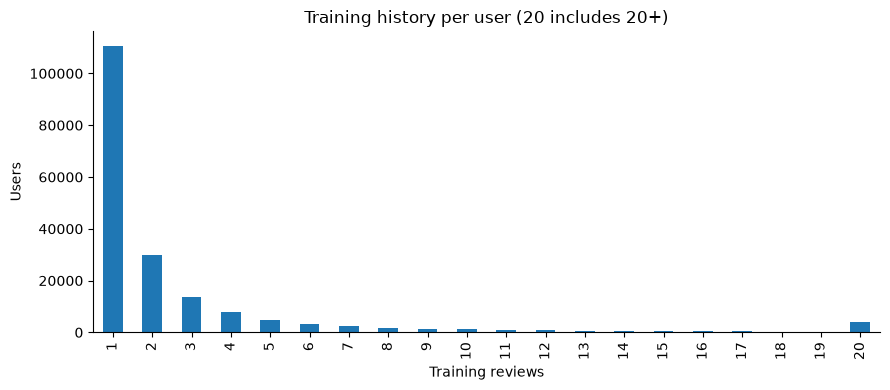

In [ ]:
history = q(
    "SELECT user_id,count(*) reviews,count(DISTINCT business_id) restaurants FROM train GROUP BY user_id"
)
items = q(
    "SELECT business_id,count(*) reviews,avg(stars) mean_stars FROM train GROUP BY business_id"
)
con.register('train_users', history)
con.register('train_items', items)

cold = q(f"""SELECT count(*) validation_reviews,
    avg(CASE WHEN u.user_id IS NULL THEN 1.0 ELSE 0 END) cold_user_fraction,
    avg(CASE WHEN i.business_id IS NULL THEN 1.0 ELSE 0 END) cold_item_fraction,
    avg(CASE WHEN coalesce(u.reviews,0)<{CFG['evaluation']['min_history']} THEN 1.0 ELSE 0 END) short_history_fraction
    FROM validation v LEFT JOIN train_users u USING(user_id) LEFT JOIN train_items i USING(business_id)""")
display(cold)
display(history[['reviews', 'restaurants']].describe(percentiles=[0.5, 0.9, 0.99]))

history.reviews.clip(upper=20).value_counts().sort_index().plot.bar(
    title="Training history per user (20 includes 20+)"
)
plt.xlabel("Training reviews")
plt.ylabel("Users")
figure('history_sparsity')

**Decision:** cold start is a normal path. Accept user-supplied location, budget, cuisines and optional liked restaurants; do not require a linkable Yelp user ID. Training-derived popularity is a reference/fallback, not evidence that a restaurant satisfies a request. No final temporal-test recommendations are scored.

## 4. Training only personalization inputs

Retain each user's full interaction history, but count each user restaurant once when constructing preferences. Use the latest training rating (stable review ID tie break); a positive profile requires that rating≥4. This avoids treating repeated reviews as extra preference votes. Personalized ranking is a later experiment, not an index prerequisite.

,count
training_users,185997
users_with_5plus_training_reviews,24077
distinct_training_pairs,595188
positive_latest_pairs,406520
users_with_positive_latest_pairs,142699


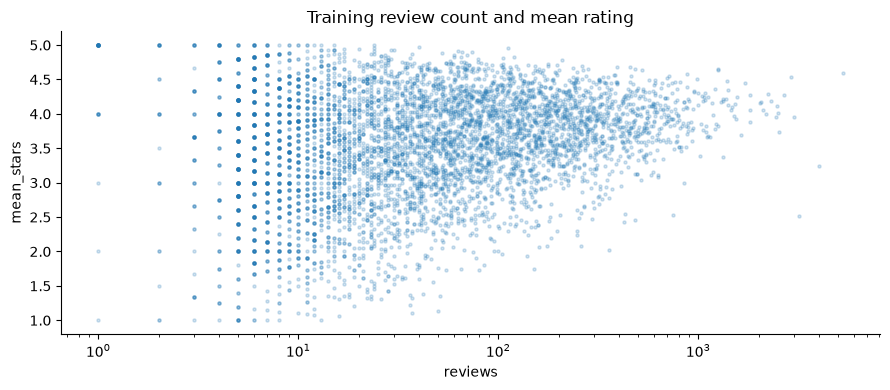

In [ ]:
latest_pairs = q("""SELECT user_id,business_id,review_id,date,stars,
    count(*) OVER(PARTITION BY user_id,business_id) interaction_count
    FROM train QUALIFY row_number() OVER(PARTITION BY user_id,business_id ORDER BY date DESC,review_id DESC)=1""")
assert latest_pairs.date.lt(pd.Timestamp(TRAIN_END)).all()
assert (
    latest_pairs.interaction_count.sum() == splits.loc[splits.split.eq('train'), 'reviews'].iloc[0]
)

profile_summary = pd.Series(
    {
        'training_users': len(history),
        'users_with_5plus_training_reviews': history.reviews.ge(CFG['evaluation']['min_history']).sum(),
        'distinct_training_pairs': len(latest_pairs),
        'positive_latest_pairs': latest_pairs.stars.ge(CFG['evaluation']['positive_stars']).sum(),
        'users_with_positive_latest_pairs': latest_pairs.loc[
            latest_pairs.stars.ge(CFG['evaluation']['positive_stars']), 'user_id'
        ].nunique(),
    }
)
display(profile_summary.to_frame('count'))

items.plot.scatter(
    x="reviews",
    y="mean_stars",
    logx=True,
    s=5,
    alpha=0.2,
    title="Training review count and mean rating",
)
figure('training_item_features')

## 5. Chosen retrieval: BM25 + EmbeddingGemma

BM25 contributes lexical matches; Gemma contributes semantic and multilingual matches. Combine restaurant ranks using equal weight reciprocal rank fusion, rather than adding incomparable raw scores. Model selection is closed by project decision.

The saved benchmark contains 240 Philadelphia restaurants, 719 pre-2020 reviews, 829 passages, 24 development queries and 8 reserved queries. It is a bounded pilot, not a full city quality estimate. The following reads completed judgments and rankings; it does not download models or repeat the discarded experiments.

In [ ]:
BENCH = EDA / 'retrieval/philadelphia_retrieval_full_v1'
# Completed expanded judgments are retained as source data, independent of old notebook code.
label_path = BENCH / 'gemma_reranking_v1/judgments.csv'
labels = pd.read_csv(label_path)
queries = pd.read_parquet(BENCH / 'queries.parquet')
dev = queries.loc[queries.partition.eq('development')]
rankings = pd.read_parquet(BENCH / 'development_rankings.parquet')
SYSTEMS = ['bm25', 'embeddinggemma', 'rrf_bm25_embeddinggemma']
rankings = rankings.loc[rankings.system.isin(SYSTEMS)].copy()
assert set(rankings.query_id) == set(dev.query_id)
assert (
    labels.relevance_grade.notna().all()
    and not labels.duplicated(['query_id', 'business_id']).any()
)
assert labels.loc[labels.constraint_pass.eq('fail'), 'relevance_grade'].eq(0).all()
assert labels.loc[labels.constraint_pass.eq('unknown'), 'relevance_grade'].le(1).all()

provenance = pd.read_csv(BENCH / 'gemma_reranking_v1/label_provenance.csv')
display(provenance.label_source.value_counts().to_frame('judgments'))
display(dev.groupby('intent').size().to_frame('development_queries'))
print("Reserved queries remain unscored:", queries.partition.eq('reserved').sum())

,judgments
label_source,
codex_ai_review,645
ai_assisted,235
ungraded,110
human_calibration,40


,development_queries
intent,
atmosphere,3
conjunction,3
cuisine,3
dietary,3
multilingual,3
negation,3
no_match,3
service,3


Reserved queries remain unscored: 8


### Interpreting relevance

Grades 0–3 describe restaurant relevance against the complete reviewed evidence bundle; ≥2 is a supported useful match. Constraint fulfillment and evidence support were graded separately. The pool mixes 40 preserved human calibration labels with 880 AI-assisted labels. Treat scores as development diagnostics, not independent human validation.

NDCG uses gains 2^grade−1. NDCG and pooled recall are undefined when a query has no pooled grade≥2; precision includes every query, including empty retrieval results. Recall is relative to the judged pool, not the full catalog. A restaurant level grade does not certify that any single selected passage supports every requested claim.

,ndcg_at_10,pooled_recall_at_10,precision_at_10
system,,,
bm25,0.478,0.415,0.196
embeddinggemma,0.573,0.457,0.233
rrf_bm25_embeddinggemma,0.566,0.542,0.242


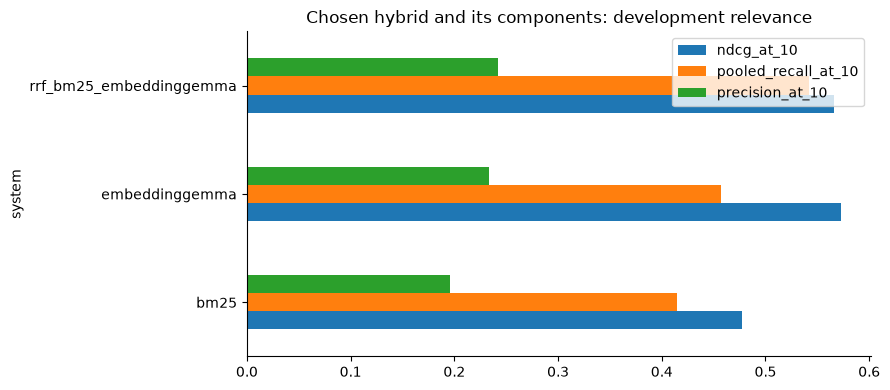

In [ ]:
lookup = labels.set_index(['query_id', 'business_id']).relevance_grade
metric_rows = []
for system in SYSTEMS:
    for query_id in dev.query_id:
        retrieved = (
            rankings.loc[rankings.system.eq(system) & rankings.query_id.eq(query_id)]
            .sort_values('rank')
            .head(10)
        )
        grades = np.array([lookup.loc[(query_id, b)] for b in retrieved.business_id])
        pool = labels.loc[labels.query_id.eq(query_id), 'relevance_grade'].to_numpy()
        ideal = np.sort(pool)[::-1][:10]
        relevant = (pool >= 2).sum()
        dcg = np.sum((2**grades - 1) / np.log2(np.arange(len(grades)) + 2))
        idcg = np.sum((2**ideal - 1) / np.log2(np.arange(len(ideal)) + 2))
        metric_rows.append(
            {
                'system': system,
                'query_id': query_id,
                'ndcg_at_10': dcg / idcg if relevant else np.nan,
                'pooled_recall_at_10': (grades >= 2).sum() / relevant if relevant else np.nan,
                'precision_at_10': (grades >= 2).sum() / 10,
            }
        )

metrics = pd.DataFrame(metric_rows).merge(dev[['query_id', 'intent']], on='query_id')
quality = (
    metrics.groupby('system')[['ndcg_at_10', 'pooled_recall_at_10', 'precision_at_10']]
    .mean()
    .reindex(SYSTEMS)
)
display(quality.round(3))
quality.plot.barh(title="Chosen hybrid and its components: development relevance")
figure('hybrid_relevance')

In [ ]:
candidate_rows = rankings.loc[
    rankings.system.eq('rrf_bm25_embeddinggemma') & rankings['rank'].le(30)
]
coverage_rows = []
for query_id in dev.query_id:
    relevant = set(
        labels.loc[labels.query_id.eq(query_id) & labels.relevance_grade.ge(2), 'business_id']
    )
    found = set(candidate_rows.loc[candidate_rows.query_id.eq(query_id), 'business_id'])
    coverage_rows.append(
        {
            'query_id': query_id,
            'relevant_in_pool': len(relevant),
            'recall_at_30': len(found & relevant) / len(relevant) if relevant else np.nan,
        }
    )

coverage = pd.DataFrame(coverage_rows)
display(coverage.loc[coverage.relevant_in_pool.eq(0), ['query_id', 'relevant_in_pool']])
print(f"Mean pooled candidate recall@30: {coverage.recall_at_30.mean():.1%}")
display(
    metrics.groupby(['system', 'intent'])[['precision_at_10']].mean().unstack('system').round(2)
)

,query_id,relevant_in_pool
1,cuisine_2,0
2,cuisine_3,0
17,negation_3,0
21,no_match_1,0
22,no_match_2,0
23,no_match_3,0


Mean pooled candidate recall@30: 92.9%


precision_at_10                                       
system                  bm25 embeddinggemma rrf_bm25_embeddinggemma
intent                                                             
atmosphere              0.40           0.10                    0.20
conjunction             0.20           0.30                    0.30
cuisine                 0.00           0.03                    0.03
dietary                 0.27           0.30                    0.33
multilingual            0.03           0.50                    0.47
negation                0.03           0.03                    0.03
no_match                0.00           0.00                    0.00
service                 0.63           0.60                    0.57

**Decision:** use the hybrid to produce 30 candidates from up to 50 eligible unique restaurants per retriever, with RRF constant 60. Mean pooled top-30 recall is 92.9% on queries with supported matches. Queries without supported evidence remain failures to explain or abstain on—not proof that no restaurant in the city could match. Similarity is not calibrated confidence or constraint satisfaction. Keep exact source passages for explanations.

## 6. Export finalized inputs and confirm build readiness

Regenerate the normalization/category/geographic exports consumed by `01_data_readiness.py`; existing raw data, analytical tables, labels and retrieval rankings remain intact. Export schemas and the anchor rule are preserved so consolidation does not silently change the chosen corpus. The script then derives Philadelphia split membership, training pairs/features and separate index eligibility.

In [14]:
(EDA / 'followup').mkdir(exist_ok=True)
normalized.to_parquet(EDA / 'restaurant_snapshot_features.parquet', index=False)
category.to_parquet(EDA / 'category_labels.parquet', index=False)
geo_audit.to_parquet(EDA / 'followup/geographic_flags.parquet', index=False)

for frame, name in [
    (summary, 'scope'),
    (splits, 'splits'),
    (metrics, 'retrieval_per_query'),
    (quality.reset_index(), 'retrieval_quality'),
    (coverage, 'candidate_coverage'),
]:
    frame.to_csv(OUT / f'{name}.csv', index=False)

runpy.run_path(str(ROOT / 'scripts/01_data_readiness.py'), run_name='__main__')
READY = ROOT / 'data/processed/philadelphia' / MANIFEST['run']
report = json.loads((READY / 'readiness.json').read_text())
assert report['decisions'] == CFG
assert report['counts']['scope_restaurants'] == len(city)
display(pd.Series(report['counts']).to_frame('count'))

{
  "scope_reviews": 687553,
  "evaluation_evidence_reviews": 613966,
  "serving_evidence_reviews": 511311,
  "scope_restaurants": 5855,
  "geography_excluded": 0,
  "serving_restaurants": 3527
}
     split  reviews  users  restaurants
     train   613966 185997         5519
validation    34936  18877         3238
      test    38651  20399         3079
Finalized data inputs: C:\Users\davis\Documents\VCCode Repos\Restaurant-Recommendation\data\processed\philadelphia\8edf7f143f8740358708c0ed78dfb83a


,count
scope_reviews,687553
evaluation_evidence_reviews,613966
serving_evidence_reviews,511311
scope_restaurants,5855
geography_excluded,0
serving_restaurants,3527


In [15]:
decisions = pd.DataFrame(
    [
        ('Scope', 'Philadelphia + PA, Restaurants-tagged', 'City-normalized selection'),
        (
            'Attributes',
            'Price, delivery, takeout, outdoor; unknown preserved',
            'Coverage and parsing above',
        ),
        (
            'Reviews',
            'All eligible reviews; no cap or sentiment filtering',
            'Preserve rare and conflicting evidence',
        ),
        (
            'Temporal evaluation',
            'Train<2020, validation2020, final2021+',
            'Separate membership; final scores sealed',
        ),
        (
            'Serving',
            'Snapshot-open businesses, all-period evidence',
            'Historical demonstration; not live status',
        ),
        (
            'Retrieval',
            'BM25 + Gemma; equal RRF60; no reranker',
            'Final project decision and judged pilot',
        ),
        (
            'Chunks',
            '220 tokens including prompt/specials; overlap32',
            'Exact source offsets; builder checks budget',
        ),
        (
            'Personalization',
            'Latest training pair rating; >=4 positive',
            'Training-only inputs; ranking remains later',
        ),
    ],
    columns=['area', 'final_choice', 'basis'],
)
display(decisions)
decisions.to_csv(OUT / 'decisions.csv', index=False)
con.close()

,area,final_choice,basis
0,Scope,"Philadelphia + PA, Restaurants-tagged",City-normalized selection
1,Attributes,"Price, delivery, takeout, outdoor; unknown preserved",Coverage and parsing above
2,Reviews,All eligible reviews; no cap or sentiment filtering,Preserve rare and conflicting evidence
3,Temporal evaluation,"Train<2020, validation2020, final2021+",Separate membership; final scores sealed
4,Serving,"Snapshot-open businesses, all-period evidence",Historical demonstration; not live status
5,Retrieval,BM25 + Gemma; equal RRF60; no reranker,Final project decision and judged pilot
6,Chunks,220 tokens including prompt/specials; overlap32,Exact source offsets; builder checks budget
7,Personalization,Latest training pair rating; >=4 positive,Training-only inputs; ranking remains later


### Next: build the indexes

```powershell
python scripts/02_build_index.py --mode evaluation
python scripts/02_build_index.py --mode serving
```

The builder and source/script tests are already verified with small real Gemma trials. Full builds are separate operations and may take substantial CPU time. Evaluation and serving artifacts remain separate. The app still requires integration; personalized ranking, grounded generation and hosting are later work.

Configuration: `config_project.yaml`. Operational details: `local_docs/hybrid_build_workflow.md`. This notebook is the single analytical walkthrough; the source retrieval artifacts remain the reproducible record of the completed pilot.